In [1]:
import pandas as pd

data = [
    # Diabetes symptoms
    ("What are the common symptoms of diabetes?", "diabetes_symptoms"),
    ("Why do I feel thirsty all the time?", "diabetes_symptoms"),
    ("Can frequent urination be a sign of diabetes?", "diabetes_symptoms"),
    ("Does diabetes cause unexplained weight loss?", "diabetes_symptoms"),
    ("Why do people with diabetes feel tired?", "diabetes_symptoms"),
    ("Can blurred vision be associated with diabetes?", "diabetes_symptoms"),

    # Causes and risk factors
    ("What causes type 2 diabetes?", "causes_risk_factors"),
    ("Does obesity increase the risk of diabetes?", "causes_risk_factors"),
    ("Is diabetes hereditary?", "causes_risk_factors"),
    ("Can lack of physical activity increase diabetes risk?", "causes_risk_factors"),
    ("What are the major risk factors for diabetes?", "causes_risk_factors"),
    ("Does family history affect diabetes risk?", "causes_risk_factors"),

    # Diagnosis and tests
    ("What is an HbA1c test?", "diagnosis_tests"),
    ("How is diabetes diagnosed?", "diagnosis_tests"),
    ("What is a fasting blood glucose test?", "diagnosis_tests"),
    ("Why do doctors recommend an oral glucose tolerance test?", "diagnosis_tests"),
    ("What blood tests detect diabetes?", "diagnosis_tests"),
    ("What does a blood glucose test measure?", "diagnosis_tests"),

    # Blood glucose monitoring
    ("How can I monitor my blood sugar at home?", "blood_glucose_monitoring"),
    ("What is a glucometer used for?", "blood_glucose_monitoring"),
    ("When should blood glucose be checked?", "blood_glucose_monitoring"),
    ("How does a continuous glucose monitor work?", "blood_glucose_monitoring"),
    ("Why should people with diabetes track glucose levels?", "blood_glucose_monitoring"),
    ("What information does a glucose reading provide?", "blood_glucose_monitoring"),

    # Medication and treatment
    ("What is insulin used for?", "medication_treatment"),
    ("How does metformin help manage diabetes?", "medication_treatment"),
    ("What are the common types of diabetes medication?", "medication_treatment"),
    ("Why might a doctor prescribe insulin?", "medication_treatment"),
    ("What is the role of medication in diabetes management?", "medication_treatment"),
    ("Can diabetes treatment differ between patients?", "medication_treatment"),

    # Diet and lifestyle
    ("What foods should people with diabetes consider eating?", "diet_lifestyle"),
    ("Why is physical activity important for diabetes management?", "diet_lifestyle"),
    ("How can a balanced diet help manage blood sugar?", "diet_lifestyle"),
    ("What are some healthy breakfast options for diabetics?", "diet_lifestyle"),
    ("Does regular exercise help with blood glucose control?", "diet_lifestyle"),
    ("Why is portion control important in diabetes?", "diet_lifestyle"),

    # Complications
    ("What complications can diabetes cause?", "complications"),
    ("Can diabetes affect kidney function?", "complications"),
    ("How can diabetes affect eyesight?", "complications"),
    ("What is diabetic neuropathy?", "complications"),
    ("Can uncontrolled diabetes affect heart health?", "complications"),
    ("Why is regular screening important for diabetes complications?", "complications"),

    # Emergency support
    ("What are the warning signs of severe low blood sugar?", "emergency_support"),
    ("What should I do if someone with diabetes becomes unconscious?", "emergency_support"),
    ("Can severe hypoglycemia be life-threatening?", "emergency_support"),
    ("What are the warning signs of diabetic ketoacidosis?", "emergency_support"),
    ("When should someone with diabetes seek emergency medical help?", "emergency_support"),
    ("What should I do if someone is confused and may have very low blood sugar?", "emergency_support"),
]

df = pd.DataFrame(data, columns=["query", "intent"])

print("Total queries:", len(df))
print("Number of intents:", df["intent"].nunique())
print("\nQueries per intent:")
print(df["intent"].value_counts())

df.head()


Total queries: 48
Number of intents: 8

Queries per intent:
intent
diabetes_symptoms           6
causes_risk_factors         6
diagnosis_tests             6
blood_glucose_monitoring    6
medication_treatment        6
diet_lifestyle              6
complications               6
emergency_support           6
Name: count, dtype: int64


,query,intent
0,What are the common symptoms of diabetes?,diabetes_symptoms
1,Why do I feel thirsty all the time?,diabetes_symptoms
2,Can frequent urination be a sign of diabetes?,diabetes_symptoms
3,Does diabetes cause unexplained weight loss?,diabetes_symptoms
4,Why do people with diabetes feel tired?,diabetes_symptoms


In [2]:
!pip install nltk -q

import nltk

nltk.download('punkt_tab')
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')

from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
import re


[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...


In [4]:
stop_words = set(stopwords.words('english'))

# Preserve medically important negation words
stop_words = stop_words - {'no', 'not', 'nor'}

def preprocess_text(text):
    # 1. Lowercase
    text = text.lower()

    # 2. Remove punctuation and special characters
    text = re.sub(r'[^a-zA-Z\s]', '', text)

    # 3. Tokenization
    tokens = word_tokenize(text)

    # 4. Stopword removal
    tokens = [
        word for word in tokens
        if word not in stop_words
    ]

    # 5. Lemmatization
    tokens = [
        lemmatizer.lemmatize(word)
        for word in tokens
    ]

    return ' '.join(tokens)

df['processed_query'] = df['query'].apply(preprocess_text)

df[['query', 'processed_query', 'intent']].head(10)


,query,processed_query,intent
0,What are the common symptoms of diabetes?,common symptom diabetes,diabetes_symptoms
1,Why do I feel thirsty all the time?,feel thirsty time,diabetes_symptoms
2,Can frequent urination be a sign of diabetes?,frequent urination sign diabetes,diabetes_symptoms
3,Does diabetes cause unexplained weight loss?,diabetes cause unexplained weight loss,diabetes_symptoms
4,Why do people with diabetes feel tired?,people diabetes feel tired,diabetes_symptoms
5,Can blurred vision be associated with diabetes?,blurred vision associated diabetes,diabetes_symptoms
6,What causes type 2 diabetes?,cause type diabetes,causes_risk_factors
7,Does obesity increase the risk of diabetes?,obesity increase risk diabetes,causes_risk_factors
8,Is diabetes hereditary?,diabetes hereditary,causes_risk_factors
9,Can lack of physical activity increase diabete...,lack physical activity increase diabetes risk,causes_risk_factors


In [5]:
print("Total queries:", len(df))
print("Unique intents:", df['intent'].nunique())
print(df['intent'].value_counts())

Total queries: 48
Unique intents: 8
intent
diabetes_symptoms           6
causes_risk_factors         6
diagnosis_tests             6
blood_glucose_monitoring    6
medication_treatment        6
diet_lifestyle              6
complications               6
emergency_support           6
Name: count, dtype: int64


In [6]:

additional_data = [
    # Diabetes symptoms
    ("What are early signs of diabetes?", "diabetes_symptoms"),
    ("Can diabetes make someone extremely hungry?", "diabetes_symptoms"),
    ("Why does diabetes cause excessive thirst?", "diabetes_symptoms"),
    ("Can slow wound healing indicate diabetes?", "diabetes_symptoms"),
    ("Does diabetes cause frequent infections?", "diabetes_symptoms"),
    ("Can tingling in the feet be a diabetes symptom?", "diabetes_symptoms"),
    ("What skin changes can occur with diabetes?", "diabetes_symptoms"),
    ("Can diabetes cause fatigue after meals?", "diabetes_symptoms"),
    ("What are the symptoms of undiagnosed diabetes?", "diabetes_symptoms"),
    ("Can increased hunger be linked to diabetes?", "diabetes_symptoms"),
    ("Do diabetes symptoms develop gradually?", "diabetes_symptoms"),
    ("Can unexplained fatigue be related to high blood sugar?", "diabetes_symptoms"),
    ("What physical changes may suggest diabetes?", "diabetes_symptoms"),
    ("Can dry mouth be associated with diabetes?", "diabetes_symptoms"),

    # Causes and risk factors
    ("Can age increase the risk of type 2 diabetes?", "causes_risk_factors"),
    ("Does being overweight increase diabetes risk?", "causes_risk_factors"),
    ("Can gestational diabetes increase future diabetes risk?", "causes_risk_factors"),
    ("Does high blood pressure increase diabetes risk?", "causes_risk_factors"),
    ("Is type 1 diabetes caused by lifestyle?", "causes_risk_factors"),
    ("Can genetics influence type 2 diabetes?", "causes_risk_factors"),
    ("Does an inactive lifestyle contribute to diabetes?", "causes_risk_factors"),
    ("Who is more likely to develop type 2 diabetes?", "causes_risk_factors"),
    ("Can a history of prediabetes increase diabetes risk?", "causes_risk_factors"),
    ("Does poor sleep affect diabetes risk?", "causes_risk_factors"),
    ("Can family medical history predict diabetes risk?", "causes_risk_factors"),
    ("Are there different risk factors for type 1 and type 2 diabetes?", "causes_risk_factors"),
    ("Does age matter when assessing diabetes risk?", "causes_risk_factors"),
    ("Can lifestyle habits influence diabetes risk?", "causes_risk_factors"),

    # Diagnosis and tests
    ("What HbA1c level is used to diagnose diabetes?", "diagnosis_tests"),
    ("How do doctors test for prediabetes?", "diagnosis_tests"),
    ("What is an oral glucose tolerance test?", "diagnosis_tests"),
    ("Why is fasting required for some glucose tests?", "diagnosis_tests"),
    ("Can a random blood sugar test detect diabetes?", "diagnosis_tests"),
    ("How often should HbA1c be tested?", "diagnosis_tests"),
    ("What does an elevated HbA1c result indicate?", "diagnosis_tests"),
    ("Which doctor can diagnose diabetes?", "diagnosis_tests"),
    ("What is the difference between fasting and random glucose tests?", "diagnosis_tests"),
    ("How is gestational diabetes diagnosed?", "diagnosis_tests"),
    ("What tests are used to detect type 1 diabetes?", "diagnosis_tests"),
    ("Can one blood test confirm diabetes?", "diagnosis_tests"),
    ("What does a glucose tolerance test measure?", "diagnosis_tests"),
    ("Why are repeat tests sometimes needed to diagnose diabetes?", "diagnosis_tests"),

    # Blood glucose monitoring
    ("How do I use a blood glucose meter?", "blood_glucose_monitoring"),
    ("What is a normal glucose reading?", "blood_glucose_monitoring"),
    ("Why should glucose readings be recorded?", "blood_glucose_monitoring"),
    ("How do test strips work in a glucometer?", "blood_glucose_monitoring"),
    ("What is a continuous glucose monitor?", "blood_glucose_monitoring"),
    ("Can exercise affect glucose readings?", "blood_glucose_monitoring"),
    ("Why should I wash my hands before testing blood sugar?", "blood_glucose_monitoring"),
    ("How can I maintain a blood sugar log?", "blood_glucose_monitoring"),
    ("What factors can affect a glucose meter reading?", "blood_glucose_monitoring"),
    ("Can glucose levels change throughout the day?", "blood_glucose_monitoring"),
    ("How does a sensor measure glucose continuously?", "blood_glucose_monitoring"),
    ("Why is monitoring important for diabetes care?", "blood_glucose_monitoring"),
    ("What should I do with unusual glucose readings?", "blood_glucose_monitoring"),
    ("How can I track glucose trends over time?", "blood_glucose_monitoring"),

    # Medication and treatment
    ("What are oral diabetes medicines?", "medication_treatment"),
    ("What is the purpose of insulin injections?", "medication_treatment"),
    ("How does diabetes medication work?", "medication_treatment"),
    ("What should I know about diabetes prescriptions?", "medication_treatment"),
    ("Can people with type 2 diabetes need insulin?", "medication_treatment"),
    ("What are the different forms of insulin?", "medication_treatment"),
    ("Why is medication adherence important in diabetes?", "medication_treatment"),
    ("Can diabetes treatment include lifestyle changes?", "medication_treatment"),
    ("What is the role of metformin in diabetes care?", "medication_treatment"),
    ("Are diabetes medicines different for each patient?", "medication_treatment"),
    ("Why should diabetes medicines be taken as prescribed?", "medication_treatment"),
    ("What are injectable treatments for diabetes?", "medication_treatment"),
    ("Who decides which diabetes medicine is suitable?", "medication_treatment"),
    ("Can diabetes treatment plans change over time?", "medication_treatment"),

    # Diet and lifestyle
    ("Which vegetables are suitable for a balanced diabetes diet?", "diet_lifestyle"),
    ("Why should sugary drinks be limited?", "diet_lifestyle"),
    ("How does walking help with blood sugar management?", "diet_lifestyle"),
    ("What is carbohydrate counting?", "diet_lifestyle"),
    ("Why is fibre important in a diabetes diet?", "diet_lifestyle"),
    ("How can meal planning support diabetes management?", "diet_lifestyle"),
    ("What role does sleep play in diabetes management?", "diet_lifestyle"),
    ("Can stress affect blood glucose levels?", "diet_lifestyle"),
    ("Why is maintaining a healthy weight important?", "diet_lifestyle"),
    ("How can physical activity improve insulin sensitivity?", "diet_lifestyle"),
    ("What are healthy snack choices for diabetes?", "diet_lifestyle"),
    ("Why should people with diabetes avoid skipping meals?", "diet_lifestyle"),
    ("How can a dietitian help someone with diabetes?", "diet_lifestyle"),
    ("What lifestyle habits support diabetes management?", "diet_lifestyle"),

    # Complications
    ("Can diabetes damage blood vessels?", "complications"),
    ("What is diabetic retinopathy?", "complications"),
    ("How can diabetes affect the nerves?", "complications"),
    ("Can diabetes cause foot problems?", "complications"),
    ("Why can diabetes increase infection risk?", "complications"),
    ("What kidney problems are associated with diabetes?", "complications"),
    ("Can diabetes increase cardiovascular risk?", "complications"),
    ("What is diabetic neuropathy?", "complications"),
    ("Why are regular eye examinations important?", "complications"),
    ("Can poorly controlled diabetes damage nerves?", "complications"),
    ("What long-term problems can high blood sugar cause?", "complications"),
    ("Why should people with diabetes check their feet?", "complications"),
    ("Can diabetes affect oral health?", "complications"),
    ("How can regular medical checkups help prevent complications?", "complications"),

    # Emergency support
    ("What are symptoms of dangerously low blood sugar?", "emergency_support"),
    ("What should I do if someone has a seizure and may have hypoglycemia?", "emergency_support"),
    ("Can unconscious people safely swallow glucose tablets?", "emergency_support"),
    ("When should emergency services be contacted for diabetes?", "emergency_support"),
    ("What are symptoms of diabetic ketoacidosis?", "emergency_support"),
    ("What should I do if someone with diabetes cannot swallow?", "emergency_support"),
    ("Can severe hypoglycemia cause confusion?", "emergency_support"),
    ("What are warning signs of a hyperglycemic emergency?", "emergency_support"),
    ("Why is vomiting with high blood sugar concerning?", "emergency_support"),
    ("What should I do if a person with diabetes becomes unresponsive?", "emergency_support"),
    ("Can diabetic ketoacidosis require hospital treatment?", "emergency_support"),
    ("When is confusion in a person with diabetes an emergency?", "emergency_support"),
    ("Should I give food to an unconscious person with suspected hypoglycemia?", "emergency_support"),
    ("What symptoms require urgent medical attention in diabetes?", "emergency_support"),
]

additional_df = pd.DataFrame(
    additional_data,
    columns=["query", "intent"]
)

df = pd.concat([df, additional_df], ignore_index=True)

df = df.drop_duplicates(subset=["query"]).reset_index(drop=True)

print("Total queries:", len(df))
print("\nQueries per intent:")
print(df["intent"].value_counts())


Total queries: 159

Queries per intent:
intent
diabetes_symptoms           20
causes_risk_factors         20
diagnosis_tests             20
blood_glucose_monitoring    20
medication_treatment        20
diet_lifestyle              20
emergency_support           20
complications               19
Name: count, dtype: int64


In [7]:

new_query = pd.DataFrame([
    (
        "How can diabetes affect circulation in the legs?",
        "complications"
    )
], columns=["query", "intent"])

df = pd.concat([df, new_query], ignore_index=True)

# Recalculate preprocessing for the complete dataset
df["processed_query"] = df["query"].apply(preprocess_text)

print("Total queries:", len(df))
print("\nQueries per intent:")
print(df["intent"].value_counts())


Total queries: 160

Queries per intent:
intent
diabetes_symptoms           20
causes_risk_factors         20
diagnosis_tests             20
blood_glucose_monitoring    20
medication_treatment        20
diet_lifestyle              20
complications               20
emergency_support           20
Name: count, dtype: int64


In [8]:

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

# Input features and target labels
X = df["processed_query"]
y = df["intent"]

# Stratified 80:20 split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Convert text into numerical TF-IDF features
tfidf = TfidfVectorizer(
    ngram_range=(1, 2),
    max_features=3000
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])
print("TF-IDF training shape:", X_train_tfidf.shape)
print("TF-IDF testing shape:", X_test_tfidf.shape)


Training samples: 128
Testing samples: 32
TF-IDF training shape: (128, 547)
TF-IDF testing shape: (32, 547)


In [9]:
from sklearn.linear_model import LogisticRegression

logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

logistic_model.fit(X_train_tfidf, y_train)

y_pred_logistic = logistic_model.predict(X_test_tfidf)

print("Logistic Regression training completed.")


Logistic Regression training completed.


In [10]:

from sklearn.naive_bayes import MultinomialNB

# Initialize Naive Bayes
nb_model = MultinomialNB()

# Train the model
nb_model.fit(X_train_tfidf, y_train)

# Predict test labels
y_pred_nb = nb_model.predict(X_test_tfidf)

print("Naive Bayes training completed.")


Naive Bayes training completed.


In [11]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

models = {
    "Logistic Regression": y_pred_logistic,
    "Naive Bayes": y_pred_nb
}

for name, predictions in models.items():
    print(f"\n{name}")
    print("-" * 40)

    print("Accuracy:",
          round(accuracy_score(y_test, predictions), 4))

    print("Precision:",
          round(precision_score(
              y_test, predictions,
              average="macro", zero_division=0
          ), 4))

    print("Recall:",
          round(recall_score(
              y_test, predictions,
              average="macro", zero_division=0
          ), 4))

    print("F1-score:",
          round(f1_score(
              y_test, predictions,
              average="macro", zero_division=0
          ), 4))

    print("\nClassification Report:")
    print(classification_report(
        y_test, predictions, zero_division=0
    ))



Logistic Regression
----------------------------------------
Accuracy: 0.8125
Precision: 0.8438
Recall: 0.8125
F1-score: 0.8057

Classification Report:
                          precision    recall  f1-score   support

blood_glucose_monitoring       0.67      1.00      0.80         4
     causes_risk_factors       1.00      1.00      1.00         4
           complications       1.00      0.75      0.86         4
       diabetes_symptoms       0.67      1.00      0.80         4
         diagnosis_tests       1.00      1.00      1.00         4
          diet_lifestyle       0.75      0.75      0.75         4
       emergency_support       0.67      0.50      0.57         4
    medication_treatment       1.00      0.50      0.67         4

                accuracy                           0.81        32
               macro avg       0.84      0.81      0.81        32
            weighted avg       0.84      0.81      0.81        32


Naive Bayes
---------------------------------------

In [12]:

# Select the better-performing model
best_model = nb_model
best_model_name = "Multinomial Naive Bayes"

print("Selected model:", best_model_name)
print("Test accuracy:",
      round(accuracy_score(y_test, y_pred_nb), 4))
print("Test macro F1-score:",
      round(f1_score(y_test, y_pred_nb, average="macro"), 4))


Selected model: Multinomial Naive Bayes
Test accuracy: 0.8438
Test macro F1-score: 0.8391


<Figure size 1200x900 with 0 Axes>

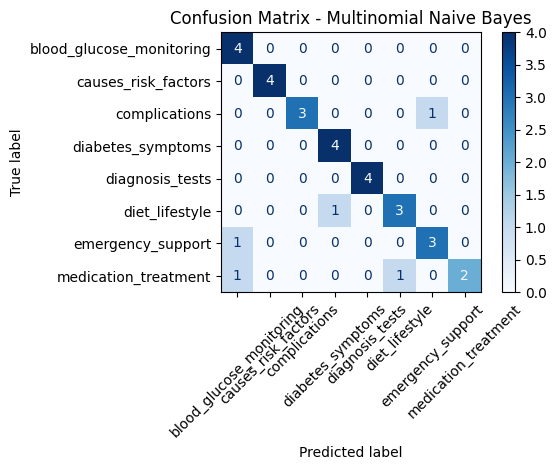

In [13]:

import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

plt.figure(figsize=(12, 9))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_nb,
    xticks_rotation=45,
    cmap="Blues"
)

plt.title("Confusion Matrix - Multinomial Naive Bayes")
plt.tight_layout()
plt.show()


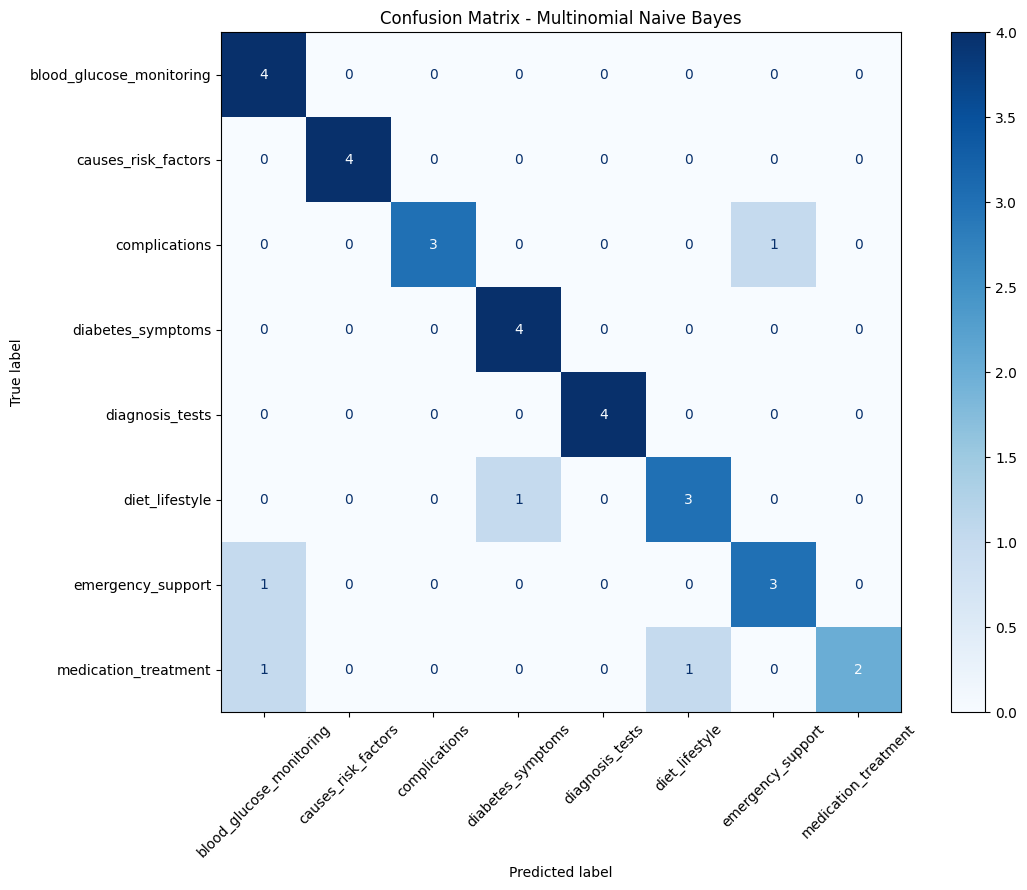

In [14]:

from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(12, 9))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_nb,
    xticks_rotation=45,
    cmap="Blues",
    ax=ax
)

ax.set_title("Confusion Matrix - Multinomial Naive Bayes")
plt.tight_layout()

plt.savefig(
    "naive_bayes_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [15]:

# Inspect prediction probabilities
sample_queries = [
    "What are the symptoms of diabetes?",
    "How does insulin work?",
    "What should I do if someone becomes unconscious?",
    "Tell me about football."
]

for query in sample_queries:
    processed = preprocess_text(query)
    vectorized = tfidf.transform([processed])

    probabilities = best_model.predict_proba(vectorized)[0]
    predicted_intent = best_model.predict(vectorized)[0]
    confidence = max(probabilities)

    print("\nQuery:", query)
    print("Predicted intent:", predicted_intent)
    print("Confidence:", round(confidence, 4))



Query: What are the symptoms of diabetes?
Predicted intent: diabetes_symptoms
Confidence: 0.2242

Query: How does insulin work?
Predicted intent: medication_treatment
Confidence: 0.2561

Query: What should I do if someone becomes unconscious?
Predicted intent: emergency_support
Confidence: 0.2834

Query: Tell me about football.
Predicted intent: blood_glucose_monitoring
Confidence: 0.125


In [16]:

knowledge_base = {
    "diabetes_symptoms": (
        "Common symptoms of diabetes may include increased thirst, "
        "frequent urination, increased hunger, fatigue, blurred vision "
        "and unexplained weight changes. Some people may have no symptoms."
    ),

    "causes_risk_factors": (
        "Risk factors for type 2 diabetes include family history, "
        "overweight or obesity, physical inactivity and increasing age. "
        "Type 1 diabetes has a different underlying cause."
    ),

    "diagnosis_tests": (
        "Diabetes can be assessed using tests such as HbA1c, fasting "
        "plasma glucose and oral glucose tolerance tests. A healthcare "
        "professional should interpret results and confirm diagnosis."
    ),

    "blood_glucose_monitoring": (
        "Blood glucose can be monitored using a glucometer or a "
        "continuous glucose monitoring device. Follow the monitoring "
        "schedule recommended by your healthcare professional."
    ),

    "medication_treatment": (
        "Diabetes treatment may include insulin, oral medicines and "
        "lifestyle management. The appropriate treatment depends on "
        "the individual and should be decided by a qualified clinician."
    ),

    "diet_lifestyle": (
        "A balanced eating pattern, regular physical activity, "
        "adequate sleep and appropriate weight management can support "
        "diabetes care. Individual dietary needs may vary."
    ),

    "complications": (
        "Diabetes may increase the risk of complications involving "
        "the eyes, kidneys, nerves, heart and blood vessels. Regular "
        "screening and medical follow-up are important."
    ),

    "emergency_support": (
        "Severe hypoglycemia and diabetic ketoacidosis can be medical "
        "emergencies. Seek urgent medical assistance when serious "
        "warning signs occur."
    )
}

print("Knowledge base created.")
print("Number of intents:", len(knowledge_base))


Knowledge base created.
Number of intents: 8


In [18]:

import re

CONFIDENCE_THRESHOLD = 0.18

# Basic vocabulary for checking whether a query relates to diabetes care
healthcare_keywords = {
    "diabetes", "diabetic", "glucose", "sugar", "insulin",
    "hba1c", "hypoglycemia", "hyperglycemia", "blood",
    "glucometer", "medicine", "medication", "metformin",
    "symptoms", "thirst", "urination", "kidney", "eyes",
    "neuropathy", "diet", "exercise", "food", "sugar",
    "fasting", "glucose", "diagnosis", "treatment",
    "unconscious", "seizure", "vomiting", "ketoacidosis",
    "hypo", "hyperglycemia"
}

emergency_patterns = [
    r"\bunconscious\b",
    r"\bunresponsive\b",
    r"\bseizure\b",
    r"\bnot breathing\b",
    r"\bcannot breathe\b",
    r"\bsevere hypoglycemia\b",
    r"\bdiabetic ketoacidosis\b",
    r"\bconfused\b.*\blow blood sugar\b"
]

def is_emergency(query):
    query = query.lower()
    return any(
        re.search(pattern, query)
        for pattern in emergency_patterns
    )

def is_healthcare_related(query):
    words = set(re.findall(r"[a-z]+", query.lower()))
    return bool(words.intersection(healthcare_keywords))

def cognitive_reasoning(query):
    # Rule 1: Emergency takes priority over classification
    if is_emergency(query):
        return (
            "EMERGENCY",
            "This may be a medical emergency. Contact local emergency "
            "services immediately. If the person is unconscious or "
            "unable to swallow safely, do not give food, liquids or "
            "tablets by mouth. Follow emergency medical instructions."
        )

    # Rule 2: Reject unrelated queries
    if not is_healthcare_related(query):
        return (
            "OUT_OF_SCOPE",
            "I can help with diabetes care information. "
            "Please ask a question related to diabetes, blood glucose, "
            "diagnosis, treatment or prevention."
        )

    # Predict intent and confidence
    processed = preprocess_text(query)
    vectorized = tfidf.transform([processed])

    probabilities = best_model.predict_proba(vectorized)[0]
    predicted_intent = best_model.predict(vectorized)[0]
    confidence = max(probabilities)

    # Rule 3: Handle low-confidence predictions
    if confidence < CONFIDENCE_THRESHOLD:
        return (
            "LOW_CONFIDENCE",
            "I could not confidently understand your question. "
            "Please rephrase it or provide more details."
        )

    # Rule 4: Retrieve response from the knowledge base
    response = knowledge_base.get(
        predicted_intent,
        "I do not have information for this query."
    )

    # Rule 5: Add healthcare disclaimer
    response += (
        "\n\nDisclaimer: This assistant provides general educational "
        "information only. It does not diagnose conditions or replace "
        "professional medical advice."
    )

    return predicted_intent, response


In [19]:

test_queries = [
    "What are the symptoms of diabetes?",
    "How does insulin work?",
    "What should I do if someone becomes unconscious?",
    "Tell me about football.",
    "Explain blood glucose monitoring."
]

for query in test_queries:
    result, response = cognitive_reasoning(query)

    print("\nQuery:", query)
    print("Result:", result)
    print("Response:", response)
    print("-" * 70)



Query: What are the symptoms of diabetes?
Result: diabetes_symptoms
Response: Common symptoms of diabetes may include increased thirst, frequent urination, increased hunger, fatigue, blurred vision and unexplained weight changes. Some people may have no symptoms.

Disclaimer: This assistant provides general educational information only. It does not diagnose conditions or replace professional medical advice.
----------------------------------------------------------------------

Query: How does insulin work?
Result: medication_treatment
Response: Diabetes treatment may include insulin, oral medicines and lifestyle management. The appropriate treatment depends on the individual and should be decided by a qualified clinician.

Disclaimer: This assistant provides general educational information only. It does not diagnose conditions or replace professional medical advice.
----------------------------------------------------------------------

Query: What should I do if someone becomes unco

In [20]:
!pip install gradio -q

In [21]:

import gradio as gr

def chatbot_response(query):
    if not query.strip():
        return "Please enter a question."

    result, response = cognitive_reasoning(query)

    return f"Category: {result}\n\n{response}"


demo = gr.Interface(
    fn=chatbot_response,
    inputs=gr.Textbox(
        lines=3,
        placeholder="Ask a question about diabetes care...",
        label="Your Question"
    ),
    outputs=gr.Textbox(
        lines=8,
        label="Cognitive Assistant Response"
    ),
    title="Diabetes Care Information Assistant",
    description=(
        "An NLP and machine-learning-based assistant "
        "for general diabetes care information."
    ),
    examples=[
        "What are the symptoms of diabetes?",
        "How does insulin work?",
        "What is an HbA1c test?",
        "How can I monitor blood glucose?",
        "What should I do if someone becomes unconscious?",
        "Tell me about football."
    ]
)

demo.launch(share=True)


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://4d967bbbefcdf3fcd0.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
